# Cobolt Laser Blink Routine
**Compact, tidy Jupyter notebook** to drive a Cobolt laser via the `pycobolt` library, cycle the emission ON/OFF, and record *actual* timing deviations.

> ⚠️ **Safety first**: Verify key‑switch and interlock are closed, wear laser goggles, and keep the beam path enclosed wherever possible.

## 1  Install / verify required packages
Skip if they’re already in your environment.

In [21]:
# !pip install -q pycobolt tqdm pandas

## 2  Imports

In [1]:
import time, csv, pathlib
from typing import Tuple, List, Optional

import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import pycobolt

## 3  Connect to the Cobolt laser
Update **`COM_PORT`** to match Device Manager (Windows) or `/dev/ttyUSB0` (Linux).

In [2]:
COM_PORT = 'COM8'   # ← change here

laser = pycobolt.CoboltLaser(port=COM_PORT)
print(f'Connected to: {laser}')

Connected to: Serial number: 19122, Model number: 0808-06-01-0120-100, Wavelength: 808 nm, Type: Cobolt06MLD


## 4  Blink routine helper

In [46]:
import os, sys, time, csv, pathlib
from typing import Tuple, Optional
import numpy as np
import pycobolt

def _set_windows_timer_resolution(ms: int = 1):
    """On Windows, request higher timer resolution (~1 ms)."""
    if sys.platform == "win32":
        try:
            import ctypes
            ctypes.windll.winmm.timeBeginPeriod(ms)
        except Exception:
            pass  # best-effort only

def _restore_windows_timer_resolution(ms: int = 1):
    if sys.platform == "win32":
        try:
            import ctypes
            ctypes.windll.winmm.timeEndPeriod(ms)
        except Exception:
            pass

def _bump_priority():
    """Best-effort: raise priority / pin CPU (platform-dependent, may require perms)."""
    try:
        if sys.platform == "win32":
            import psutil, win32process, win32con
            p = psutil.Process()
            p.nice(psutil.REALTIME_PRIORITY_CLASS)
            # Optional: pin to first CPU
            win32process.SetProcessAffinityMask(win32process.GetCurrentProcess(), 0x0001)
        else:
            os.nice(-10)  # may fail without privileges
            try:
                import psutil
                p = psutil.Process()
                p.nice(-10)
                p.cpu_affinity([0])
            except Exception:
                pass
    except Exception:
        pass

def laser_routine_tight(
    laser: pycobolt.CoboltLaser,
    power_mw: float,
    on_s: float,
    off_s: float,
    n_cycles: int,
    *,
    log_csv: Optional[pathlib.Path] = None,
    show_plot: bool = True,     # kept for API compatibility; plotting done after
    progress: bool = False,     # default False to avoid UI overhead in the hot loop
    spin_window_s: float = 0.001,  # last 1 ms busy-wait window
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Attempt lower-jitter ON/OFF timing from Python by:
    - absolute scheduling on a monotonic clock
    - long sleep + short spin-wait
    - zero I/O inside the hot loop
    """
    if power_mw <= 0 or on_s <= 0 or off_s <= 0:
        raise ValueError("power_mw, on_s, and off_s must all be > 0")
    if n_cycles < 1:
        raise ValueError("n_cycles must be ≥ 1")
    if spin_window_s < 0:
        raise ValueError("spin_window_s must be ≥ 0")

    _set_windows_timer_resolution(1)
    _bump_priority()

    on_dev   = np.empty(n_cycles, dtype=np.float64)
    off_dev  = np.empty(n_cycles, dtype=np.float64)
    # Optional memory buffer for CSV; fuller rows written after the loop
    log_rows = [] if log_csv else None

    # Precompute absolute deadlines (edges): [ON, OFF, ON, OFF, ...]
    period = on_s + off_s
    now0 = time.perf_counter()  # monotonic
    # We will toggle: ON at t0, OFF at t0+on, ON at t0+period, OFF at t0+period+on, ...
    t0 = now0 + 0.05  # small lead-in to settle
    next_on  = t0
    next_off = t0 + on_s

    try:
        laser.constant_power(power_mw)
        # initial state: make sure off before starting absolute schedule
        laser.turn_off()

        # Helper: sleep-most-then-spin-until(deadline)
        def sleep_then_spin(deadline: float):
            while True:
                now = time.perf_counter()
                dt = deadline - now
                if dt <= 0:
                    break
                if dt > spin_window_s:
                    # sleep the chunk minus spin window
                    time.sleep(dt - spin_window_s)
                else:
                    # spin
                    while time.perf_counter() < deadline:
                        pass
                    break

        for k in range(n_cycles):
            # ---------- ON edge ----------
            sleep_then_spin(next_on)
            tic = time.perf_counter()
            laser.turn_on()
            # Measure command latency relative to deadline
            on_dev[k] = (time.perf_counter() - tic) + (tic - next_on)

            # ---------- OFF edge ----------
            sleep_then_spin(next_off)
            tic = time.perf_counter()
            laser.turn_off()
            off_dev[k] = (time.perf_counter() - tic) + (tic - next_off)

            # Schedule next cycle’s absolute deadlines
            next_on  += period
            next_off += period

        # Write CSV once, outside timing loop
        if log_csv:
            log_csv = pathlib.Path(log_csv)
            with log_csv.open("w", newline="") as f:
                writer = csv.writer(f)
                writer.writerow(["cycle", "phase", "planned_s", "deviation_s"])
                for k in range(n_cycles):
                    writer.writerow([k, "on",  on_s,  on_dev[k]])
                    writer.writerow([k, "off", off_s, off_dev[k]])

    finally:
        try:
            laser.turn_off()
        finally:
            laser.disconnect()
            _restore_windows_timer_resolution(1)

    # Quick stats
    def stats(arr): 
        m = float(np.mean(arr)) if arr.size else 0.0
        s = float(np.std(arr, ddof=1)) if arr.size > 1 else 0.0
        return f"{m:.6f} ± {s:.6f} s"
    print(f"\nPlanned ON  : {on_s:.6f} s   → deviation {stats(on_dev)}")
    print(f"Planned OFF : {off_s:.6f} s   → deviation {stats(off_dev)}")

    # Optional plot kept identical to your original (call it outside the hot loop)
    if show_plot:
        import matplotlib.pyplot as plt
        idx = np.arange(n_cycles)
        plt.figure(figsize=(6, 4))
        plt.scatter(idx, on_dev,  label="ON",  marker="o")
        plt.scatter(idx, off_dev, label="OFF", marker="x")
        plt.axhline(0, ls="--", lw=0.8)
        plt.xlabel("Cycle #")
        plt.ylabel("Timing error (s)")
        plt.title("Cobolt laser timing deviations (tight loop)")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return on_dev, off_dev


## 5  Run the routine

Blink cycles:   0%|          | 0/200 [00:00<?, ?cy/s]


Planned ON  : 0.0500 s   → deviation 0.0091 ± 0.0063 s
Planned OFF : 0.0500 s   → deviation 0.0095 ± 0.0056 s


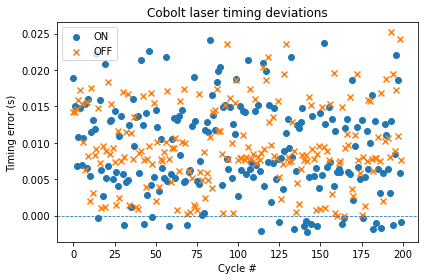

In [61]:
laser = pycobolt.CoboltLaser(port=COM_PORT)
on_err, off_err = laser_routine(
    laser,
    power_mw=100,   # mW
    on_s=0.05,      # ON dwell
    off_s=0.05,     # OFF dwell
    n_cycles=200,
    log_csv="test.csv",  # or "blink_log.csv"
)
laser.disconnect()

## 6  Run the routine

In [10]:
laser.disconnect()